# Case Study 7 — Real-Time Fraud Screening: Which Signals Matter, and Should Rules Differ by Business Line? (Velocity, Graph, Anomaly)

**Priority:** ★★ Good to have · **Reference:** Case Study 7 — *Cashfree RiskShield: real-time fraud screening with velocity, graph and anomaly signals* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Risk, Merchant Risk Operations, Product (RiskShield), Finance
**Data:** ⚠️ **SYNTHETIC** (D-7-01). Merchant fraud logs are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs07_velocity_graph_fraud_screening.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on Cashfree RiskShield's documented design; Cashfree disclosed no impact numbers. Written after the analysis.)*

- **The question:** which of the seven signal families actually catch fraud, should allow/review/block thresholds differ by business line, and what is each worth in ₹?
- **Velocity counters are the workhorse.** "≥ 5 accounts on one IP in 24 h" and "≥ 5 payments from one device in 10 minutes" are right 99.6–99.9% of the time when they fire. Removing the velocity family costs the most: AUC 0.974 → 0.891. The right window depends on the attack: **10–60 minutes for card-testing bots, 7 days for promo abuse and stolen-card rings**.
- **A model beats hand-written rules on both sides of the trade-off.** Over the 3 test weeks, the hand rules cut fraud + friction cost from ₹25.8 lakh (allow everything) to ₹15.0 lakh, but **block 0.91% of genuine customers** (guardrail: 0.5%). The gradient-boosting score with cost-optimal thresholds reaches **₹8.7 lakh while blocking only 0.04%** of genuine customers.
- **Three documented ideas did *not* pay off here, which is useful to know:**
  - **Per-business-line thresholds** saved nothing over one global pair (−₹0.02 lakh, CI −0.21 to +0.13), because the model already uses the business line and amount.
  - **Weekly retraining** caught the same frauds as a static model while attack patterns were stable (64% vs 64%, p = 0.51).
  - An **unsupervised anomaly score** caught card-testing bots (83%) but almost none of a "never-seen" promo-abuse attack (8% vs 6%, p = 0.29).
- **What *did* pay off:**
  - A **trusted-customer allowlist** cuts genuine reviews by 25% with no extra fraud.
  - **As-of graph features** are essential. Built with hindsight they make the model look perfect (AUC 0.9999), a leak that would fail in production.
- **₹ impact (scaled to ≈ 15 lakh transactions/month):** the model + allowlist saves ≈ **₹2.5 crore/month vs allowing everything** and **≈ ₹96 lakh/month more than the hand rules**. Velocity is the most valuable family (≈ ₹1.1 crore/month if dropped). Every family earns its keep in ₹ terms.
- **I recommend:** replace hand rules with a cost-thresholded model (one global threshold pair, re-tuned monthly on matured labels), keep the velocity counters at attack-specific windows, add the trusted-customer allowlist, and treat a new attack as an analyst-written velocity rule first, since neither the model nor the anomaly score sees it.

## 1. The Problem in Simple English

Online merchants (gaming apps, e-commerce stores, ed-tech subscriptions) are attacked in three typical ways:
- **Card testing:** bots try dozens of stolen card numbers in minutes with ₹1–₹50 payments, to find out which cards work.
- **Stolen-card purchases:** fraudsters buy expensive items with stolen cards. The real cardholder disputes the charge weeks later (a **chargeback**), and the merchant loses the money plus a fee.
- **Promotion abuse:** one person creates many fake accounts on a few phones to claim "first order ₹200 off" again and again.

Each payment must be **allowed, sent for manual review, or blocked** within milliseconds. Blocking too much loses good customers; blocking too little loses money. Cashfree's RiskShield combines seven kinds of signals (negative lists, disposable contacts, device checks, geo/IP, anomaly scores, **velocity** counters and **graph** links) and lets merchants tune rules **by business line**.

This notebook answers four practical questions: **Which signals actually catch fraud? Are velocity and graph features worth building? Should thresholds differ by business line? And how much ₹ does each choice save?**

## 2. Reference from the Case File

### (a) What Cashfree did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "UPI collect-request scams, chargeback fraud and promotion abuse"; screening "in real time" |
| Question | "Should this transaction be allowed, challenged or blocked, given who is transacting, from which device and location, how fast, and who they are linked to?" |
| Signals (7 groups) | Negative lists ("including from regulators"); contact intelligence (disposable phone/email); device; geo/IP; anomaly scores; **velocity** (">X distinct mobile numbers or devices within Y time"); **graph** ("links to already-proven risky entities") |
| Approach | Feature families → anomaly scoring → "rule engine tuned by the merchant's **line of business and transaction size**" → post-processing "to cut false positives" → feedback loop that "auto-tunes features and thresholds" → human-readable explanations |
| Statistics / ML | Statistics: ND. "Advanced anomaly detection algorithms" (not named). Target / validation / metrics: ND |
| Tech | Apache Flink, Kafka, graph DB; "up to **12,000 screenings/second**" |
| Impact | **Not publicly disclosed** |

**Source:** "Cashfree RiskShield: fraud prevention tech, part 2", 9 May 2025 — https://www.cashfree.com/blog/cashfree-riskshield-fraud-prevention-tech-part-2/

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | ≈ 279k transactions over 8 weeks from ≈ 60k genuine customers at merchants in 3 business lines, plus 45 card-testing bots, 18 stolen-card rings + 250 lone fraudsters, and 110 promo abusers. Fraud ≈ 1.35% of transactions. Realistic confounders: households sharing phones, ₹1 mandate-verification charges, travellers with IP/card-state mismatch, fraudsters on residential proxies. |
| Signals built | All 7 families, computed **as of the transaction time** (velocity in 10-min to 7-day windows; graph links to entities whose fraud was *already confirmed*; daily-snapshot connected components) |
| Statistics added (the source disclosed none) | Signal lift with Wilson/Katz CIs and Holm; velocity-window choice with DeLong; drop-one-family incremental value (DeLong, Holm); graph **look-ahead leakage** test; anomaly vs supervised on a **never-seen attack**; cost-optimal allow/review/block thresholds **per business line vs global** with paired bootstrap; allowlist post-processing; static vs weekly-retrained feedback loop (McNemar); reason-code validity (Cramér's V); power |

### (c) How the industry uses this

Every Indian payment gateway and large merchant runs this stack: Razorpay Thirdwatch, Cashfree RiskShield, PayU, Juspay, and in-house teams at Swiggy, Dream11 and BYJU'S-type ed-tech. **Velocity counters and entity-link graphs are the workhorse features of payment fraud.** RBI's 2024–25 push on mule accounts and the NPCI/I4C fraud registries are building exactly the "negative lists from regulators" that RiskShield consumes.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which signals should we build and pay for, and should allow/review/block rules be set per business line? |
| Analytical | (1) Which signals separate fraud from genuine traffic, and by how much? (2) Does each family add value on top of the others out-of-time? (3) Do per-line thresholds lower total fraud + friction cost vs one global threshold? |

**Hypotheses**
- **H1 (signals):** for each binary signal, H0: fraud rate is the same with and without the signal (Fisher/χ², Holm).
- **H2 (families):** for each family, H0: removing it does not reduce out-of-time AUC (DeLong, Holm across 6 families).
- **H3 (graph leakage):** H0: graph features built with hindsight labels give the same AUC as as-of features (we *expect* to reject: leakage).
- **H4 (line-specific thresholds):** H0: expected cost per transaction is equal under per-line and global thresholds (paired bootstrap on test transactions).
- **H5 (feedback loop):** H0: a weekly-retrained model catches the same frauds as a static one (McNemar).

**Primary metric:** **total expected cost** = fraud losses let through + margin lost on blocked or abandoned genuine customers + review cost. **Secondary:** recall at a 1% alert budget, PR-AUC. **Guardrail:** genuine-customer block rate ≤ 0.5% per line. **Design:** train weeks 1–4 (labels as known on day 28) → tune thresholds on week 5 → **test weeks 6–8**.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier as HGB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public transaction-level fraud data with device/IP/velocity/graph fields | **None usable.** The ULB credit-card and IEEE-CIS sets are Kaggle-hosted (excluded by the brief) and anonymised, with no linkable entities. PaySim (mobile money, synthetic) has no device/IP/promo signals. |
| **Decision** | Synthetic transactions with the seven documented signal groups (D-7-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs07.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 7 (Cashfree RiskShield-style real-time fraud screening)
=============================================================================================
THIS DATA IS SYNTHETIC. Merchant transaction and fraud logs are confidential.

8 weeks of card/UPI checkout transactions at merchants in three business lines
(online gaming, e-commerce, ed-tech subscriptions), screened in real time. Fraud types:
  * card_testing  - bots try many stolen cards in minutes with tiny amounts (datacenter IPs)
  * stolen_card   - high-value purchases on stolen cards; rings share devices/IPs; geo mismatch;
                    confirmed by chargeback 10-60 days later
  * promo_abuse   - one person creates many new accounts on a few devices with disposable
                    emails/phones to farm sign-up offers
Seven signal groups (as documented): negative lists, contact intelligence (disposable phone/email),
device intelligence (emulator, device age), geo/IP, anomaly scores, velocity, graph links.
Negative lists are partial (only some fraudsters listed) and stale (some legitimate users listed).

Calibration anchors (reference file, Case Study 7): fraud types "UPI collect-request scams,
chargeback fraud and promotion abuse"; velocity ">X distinct mobile numbers or devices within Y time";
rules "tuned by the merchant's line of business and transaction size"; no impact numbers disclosed.
Rates are our assumptions (decision.md D-7-02). Hidden columns start with "_".

Output: data/cs07/transactions.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-03-02"); DAYS = 56
LINES = ["gaming", "ecommerce", "edtech"]
STATES = ["MH", "KA", "DL", "TN", "TG", "UP", "GJ", "WB", "RJ", "KL"]


def _ts(rng, n, d0=0, d1=DAYS):
    day = rng.uniform(d0, d1, n); hr = rng.choice(24, n, p=np.r_[[0.6] * 6, [3] * 4, [5] * 8, [6] * 4, [2] * 2] / np.r_[[0.6] * 6, [3] * 4, [5] * 8, [6] * 4, [2] * 2].sum())
    return START + pd.to_timedelta(np.floor(day) * 86400 + hr * 3600 + rng.uniform(0, 3600, n), unit="s")


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    # ---------------- legitimate customers ----------------
    n_c = 60_000
    line_c = rng.choice(LINES, n_c, p=[0.3, 0.5, 0.2]); st = rng.choice(STATES, n_c)
    disp = rng.random(n_c) < 0.03
    k = rng.poisson(rng.gamma(1.2, 3.0, n_c)) + 1
    ci = np.repeat(np.arange(n_c), k); N = len(ci)
    first = np.r_[1, (np.diff(ci) != 0).astype(int)]
    ts = _ts(rng, N)
    cid = np.array([f"{i:06d}" for i in range(n_c)])[ci]
    hh = rng.random(n_c) < 0.08                                                            # households sharing a phone/laptop
    hh_of = np.where(hh, np.maximum(np.arange(n_c) - rng.integers(1, 4, n_c), 0), np.arange(n_c))
    hh_cid = np.array([f"{i:06d}" for i in range(n_c)])[hh_of][ci]
    second_card = (rng.random(n_c) < 0.2)[ci]
    leg = pd.DataFrame({"ts": ts, "customer_id": np.char.add("C", cid), "business_line": line_c[ci],
                        "device_id": np.where(rng.random(N) < 0.1, np.char.add(np.char.add("D", cid), "b"), np.char.add("D", hh_cid)),
                        "ip": np.where(rng.random(N) < 0.7, [f"IP{i % 9000:05d}" for i in ci], [f"IPM{x:06d}" for x in rng.integers(0, 400000, N)]),
                        "ip_type": np.where(rng.random(N) < 0.97, "residential_or_mobile", "datacenter_or_vpn"),
                        "ip_state": np.where(rng.random(N) < 0.80, st[ci], rng.choice(STATES, N)), "bin_state": st[ci],
                        "card_hash": np.where(second_card & (rng.random(N) < 0.5), np.char.add(np.char.add("K", cid), "x"), np.char.add("K", cid)),
                        "phone_hash": np.char.add("P", cid), "email_type": np.where(disp[ci], "disposable", "regular"),
                        "emulator": (rng.random(N) < 0.006).astype(int),
                        "device_age_days": np.where(rng.random(N) < 0.15, rng.uniform(0, 30, N), np.maximum(0, rng.normal(250, 150, N))).round(),
                        "new_account": first, "promo_used": (rng.random(N) < np.where(first == 1, 0.35, 0.06)).astype(int),
                        "amount_inr": np.round(np.exp(rng.normal(pd.Series(line_c[ci]).map({"gaming": np.log(350), "ecommerce": np.log(1100), "edtech": np.log(2600)}).to_numpy(), 0.8))),
                        "_type": "legit"})
    verify = rng.random(N) < 0.03                                                          # Rs 1 mandate / card verification charges
    leg.loc[verify, "amount_inr"] = rng.choice([1.0, 2.0, 5.0], verify.sum())
    # first transaction of each customer happens first in time
    leg["ts"] = leg.groupby("customer_id").ts.transform(np.sort)
    # ---------------- card-testing bots ----------------
    ct = []
    for b in range(45):
        t0 = _ts(rng, 1)[0]; ncard = rng.integers(15, 60); dev = f"BOT{b:03d}"; ip = f"IPDC{b % 15:03d}"
        line = rng.choice(["gaming", "ecommerce"], p=[0.6, 0.4]); proxy = rng.random() < 0.4; big = rng.random() < 0.3
        ct.append(pd.DataFrame({"ts": t0 + pd.to_timedelta(np.sort(rng.uniform(0, rng.uniform(900, 5400), ncard)), unit="s"),
                                "customer_id": [f"CT{b:03d}_{j:02d}" for j in range(ncard)], "business_line": line, "device_id": dev, "ip": ip,
                                "ip_type": "residential_or_mobile" if proxy else "datacenter_or_vpn", "ip_state": rng.choice(STATES), "bin_state": rng.choice(STATES, ncard),
                                "card_hash": [f"KS{b:03d}{j:02d}" for j in range(ncard)], "phone_hash": f"PB{b:03d}", "email_type": rng.choice(["regular", "disposable"]),
                                "emulator": int(rng.random() < 0.5), "device_age_days": 0.0, "new_account": 1, "promo_used": 0,
                                "amount_inr": (rng.choice([99, 149, 199, 499], ncard) if big else rng.choice([1, 2, 5, 10, 49], ncard)).astype(float), "_type": "card_testing"}))
    # ---------------- stolen-card rings ----------------
    sc = []
    for r in range(18):
        devs = [f"RDEV{r:02d}{j}" for j in range(3)]; ips = [f"IPR{r:02d}{j}" for j in range(4)]; t_ring = rng.uniform(0, DAYS - 10)
        for a in range(rng.integers(6, 14)):
            n = rng.integers(2, 7); ts = _ts(rng, n, t_ring, min(DAYS, t_ring + 14))
            sc.append(pd.DataFrame({"ts": ts, "customer_id": f"SC{r:02d}_{a:02d}", "business_line": rng.choice(LINES, p=[0.25, 0.45, 0.3]),
                                    "device_id": rng.choice(devs, n), "ip": np.where(rng.random(n) < 0.6, [f"IP{x:05d}" for x in rng.integers(0, 9000, n)], rng.choice(ips, n)), "ip_type": np.where(rng.random(n) < 0.45, "datacenter_or_vpn", "residential_or_mobile"),
                                    "ip_state": "SAME", "bin_state": rng.choice(STATES), "card_hash": [f"KR{r:02d}{a:02d}{x}" for x in rng.integers(0, 3, n)],
                                    "phone_hash": f"PR{r:02d}{a:02d}", "email_type": "disposable" if rng.random() < 0.4 else "regular",
                                    "emulator": (rng.random(n) < 0.15).astype(int), "device_age_days": rng.integers(0, 200, n).astype(float), "new_account": np.r_[1, np.zeros(n - 1, int)],
                                    "promo_used": 0, "amount_inr": np.round(np.exp(rng.normal(np.log(3000), 0.9, n))), "_type": "stolen_card"}))
    # lone stolen-card fraudsters (no ring)
    for a in range(250):
        n = rng.integers(1, 4); ts = _ts(rng, n)
        sc.append(pd.DataFrame({"ts": ts, "customer_id": f"SL{a:03d}", "business_line": rng.choice(LINES, p=[0.25, 0.45, 0.3]),
                                "device_id": f"LDEV{a:03d}", "ip": f"IP{rng.integers(0, 9000):05d}" if rng.random() < 0.6 else f"IPL{a:03d}", "ip_type": np.where(rng.random(n) < 0.3, "datacenter_or_vpn", "residential_or_mobile"),
                                "ip_state": "SAME", "bin_state": rng.choice(STATES), "card_hash": f"KL{a:03d}", "phone_hash": f"PL{a:03d}",
                                "email_type": "disposable" if rng.random() < 0.25 else "regular", "emulator": 0, "device_age_days": rng.integers(0, 365, n).astype(float),
                                "new_account": np.r_[1, np.zeros(n - 1, int)], "promo_used": 0, "amount_inr": np.round(np.exp(rng.normal(np.log(2500), 0.9, n))), "_type": "stolen_card"}))
    # ---------------- promo abusers ----------------
    pa = []
    for u in range(110):
        ndev = rng.integers(2, 4); t0 = rng.uniform(0, DAYS - 7); line = rng.choice(["ecommerce", "gaming"], p=[0.65, 0.35])
        for a in range(rng.integers(3, 13)):
            pa.append(pd.DataFrame({"ts": _ts(rng, 1, t0, t0 + 7), "customer_id": f"PA{u:03d}_{a:02d}", "business_line": line,
                                    "device_id": f"PDEV{u:03d}{rng.integers(ndev)}", "ip": f"IP{rng.integers(0, 9000):05d}" if rng.random() < 0.5 else f"IPP{u:03d}",
                                    "ip_type": "residential_or_mobile", "ip_state": rng.choice(STATES), "bin_state": rng.choice(STATES),
                                    "card_hash": f"KP{u:03d}{rng.integers(3)}", "phone_hash": f"PP{u:03d}{a:02d}", "email_type": "disposable" if rng.random() < 0.5 else "regular",
                                    "emulator": int(rng.random() < 0.15), "device_age_days": float(rng.integers(5, 400)), "new_account": 1, "promo_used": int(rng.random() < 0.85),
                                    "amount_inr": float(np.round(np.exp(rng.normal(np.log(450), 0.4)))), "_type": "promo_abuse"}))
    df = pd.concat([leg] + ct + sc + pa, ignore_index=True)
    df["is_fraud"] = (df._type != "legit").astype(int)
    same = df.ip_state == "SAME"                                                          # fraudsters on same-state proxies half the time
    df.loc[same, "ip_state"] = np.where(rng.random(same.sum()) < 0.5, df.loc[same, "bin_state"], rng.choice(STATES, same.sum()))
    n = len(df)
    # outcome of the payment attempt (card testing mostly declined)
    p_ok = np.where(df._type == "card_testing", 0.15, np.where(df._type == "stolen_card", 0.8, 0.95))
    df["payment_status"] = np.where(rng.random(n) < p_ok, "success", "declined")
    # label arrival: chargebacks late; card testing / promo abuse found by investigation within days
    delay = np.where(df._type == "stolen_card", rng.uniform(10, 60, n), rng.uniform(1, 5, n))
    df["label_date"] = np.where(df.is_fraud == 1, df.ts + pd.to_timedelta(delay, unit="D"), pd.NaT)
    df["label_date"] = pd.to_datetime(df.label_date)
    # negative lists: 25% of fraud actors' phone or device listed beforehand; 0.25% of legit phones listed (stale)
    actors = df[df.is_fraud == 1].customer_id.str.split("_").str[0].unique()
    listed_actor = set(rng.choice(actors, int(0.25 * len(actors)), replace=False))
    legit_ph = df.loc[df.is_fraud == 0, "phone_hash"].unique()
    listed_ph = set(rng.choice(legit_ph, int(0.0025 * len(legit_ph)), replace=False))
    df["negative_list_hit"] = (df.customer_id.str.split("_").str[0].isin(listed_actor) | df.phone_hash.isin(listed_ph)).astype(int)
    df["phone_type"] = np.where((df.is_fraud == 1) & (rng.random(n) < 0.35), "virtual_or_disposable", np.where(rng.random(n) < 0.02, "virtual_or_disposable", "regular"))
    df["merchant_id"] = [f"{l[:2].upper()}{m:03d}" for l, m in zip(df.business_line, rng.integers(0, 40, n))]
    df = df.sort_values("ts").reset_index(drop=True)
    df.insert(0, "txn_id", [f"T{i:08d}" for i in range(1, n + 1)])
    # data-quality defects
    df.loc[df.sample(frac=0.01, random_state=seed).index, "device_id"] = np.nan                # SDK did not send device id
    df = pd.concat([df, df.sample(n=800, random_state=seed + 1)], ignore_index=True)           # duplicate events from retries
    df.loc[df.sample(n=150, random_state=seed + 2).index, "amount_inr"] = -df.amount_inr         # sign error (refund rows mis-tagged)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs07"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs07", "transactions.csv.gz"), index=False)
    dd = d.drop_duplicates("txn_id")
    print(len(dd), "txns", dd.customer_id.nunique(), "customers | fraud rate", dd.is_fraud.mean().round(4))
    print(dd.groupby("_type").size().to_dict()); print(dd.groupby("business_line").is_fraud.mean().round(4).to_dict())
    print("neg list hit rate fraud/legit", dd.groupby("is_fraud").negative_list_hit.mean().round(4).to_dict())

Overwriting data/generate_cs07.py


In [3]:
os.makedirs("data/cs07", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs07 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs07/transactions.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.txn_id.nunique():,} unique transactions")
raw.drop(columns=["_type"]).sample(3, random_state=SEED).T

280,139 rows | 279,339 unique transactions


,122240,41612,115186
txn_id,T00122241,T00041613,T00115187
ts,2026-03-26 16:09:13.730569942,2026-03-10 13:24:25.809883459,2026-03-25 08:24:25.138438807
customer_id,C052330,C003024,C035671
business_line,gaming,ecommerce,ecommerce
device_id,D052330b,D003024,D035671
ip,IP07330,IP03024,IPM033226
ip_type,residential_or_mobile,residential_or_mobile,residential_or_mobile
ip_state,KA,MH,MH
bin_state,KA,MH,MH
card_hash,K052330x,K003024,K035671


| Parameter | Value | Basis |
|---|---|---|
| Lines | gaming 30% (₹350 median), e-commerce 50% (₹1,100), ed-tech 20% (₹2,600) | Our assumption |
| Card testing | 45 bot sessions, 15–60 cards in 15–90 min, ₹1–49 (30% of bots ₹99–499), 40% via residential proxies | Typical card-testing pattern |
| Stolen card | 18 rings sharing devices/IPs + 250 lone fraudsters; ₹2,500–3,000 median; half use same-state proxies; **chargeback 10–60 days later** | **Documented** "chargeback fraud" |
| Promo abuse | 110 people × 3–12 accounts on 2–3 devices; disposable email 50% | **Documented** "promotion abuse" |
| Hard negatives | 8% of customers share a device (households); 20% IP-state ≠ card-state (travel/migration); 3% ₹1–5 verification charges; 15% new phones | Realism |
| Negative lists | 25% of fraud actors pre-listed; **0.25% of genuine phones listed (stale)** | **Documented** source; coverage ours |
| DQ issues | 800 duplicate events; 1% missing device ID; 150 negative amounts (mis-tagged refunds) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("txn_id, ts, business_line, merchant_id", "Transaction identity, time, merchant line (gaming / ecommerce / edtech)"),
    ("customer_id, device_id, ip, card_hash, phone_hash", "Entity tokens (graph nodes)"), ("ip_type, ip_state, bin_state", "Geo/IP: datacenter/VPN flag; IP state vs card-issuing state"),
    ("email_type, phone_type", "Contact intelligence: disposable / virtual"), ("emulator, device_age_days, new_account", "Device intelligence"),
    ("negative_list_hit", "Any entity on a negative list (incl. regulator lists)"), ("amount_inr, promo_used, payment_status", "Value, promo code used, success/declined"),
    ("is_fraud, label_date", "Confirmed fraud and when it was confirmed"), ("_type", "HIDDEN truth: legit / card_testing / stolen_card / promo_abuse (used only for cost and diagnostics)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs07/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"txn_id, ts, business_line, merchant_id","Transaction identity, time, merchant line (gam..."
1,"customer_id, device_id, ip, card_hash, phone_hash",Entity tokens (graph nodes)
2,"ip_type, ip_state, bin_state",Geo/IP: datacenter/VPN flag; IP state vs card-...
3,"email_type, phone_type",Contact intelligence: disposable / virtual
4,"emulator, device_age_days, new_account",Device intelligence
5,negative_list_hit,Any entity on a negative list (incl. regulator...
6,"amount_inr, promo_used, payment_status","Value, promo code used, success/declined"
7,"is_fraud, label_date",Confirmed fraud and when it was confirmed
8,_type,HIDDEN truth: legit / card_testing / stolen_ca...


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs07/transactions.csv.gz", parse_dates=["ts", "label_date"])
checks = {"duplicate txn_id (retry events)": int(df.txn_id.duplicated().sum()), "device_id missing (SDK gap)": int(df.device_id.isna().sum()),
          "negative amount (mis-tagged refunds)": int((df.amount_inr < 0).sum()), "fraud without label_date": int(((df.is_fraud == 1) & df.label_date.isna()).sum()),
          "label_date before transaction": int((df.label_date < df.ts).sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("txn_id").copy()
df = df[df.amount_inr > 0].copy()                                         # refunds are not screening events
df["device_id"] = df.device_id.fillna("UNKNOWN_DEV")
df = df.sort_values("ts").reset_index(drop=True)
print(f"\nClean: {len(df):,} transactions | fraud rate {df.is_fraud.mean():.2%} | by type {df._type.value_counts().to_dict()}")
print("Fraud rate by line:", df.groupby("business_line").is_fraud.mean().round(4).to_dict())

duplicate txn_id (retry events)          800
device_id missing (SDK gap)             2797
negative amount (mis-tagged refunds)     150
fraud without label_date                   0
label_date before transaction              0



Clean: 279,189 transactions | fraud rate 1.35% | by type {'legit': 275409, 'card_testing': 1774, 'stolen_card': 1161, 'promo_abuse': 845}
Fraud rate by line: {'ecommerce': 0.0134, 'edtech': 0.0056, 'gaming': 0.019}


**Observation:** we removed **800 duplicate events** (payment retries that would double-count), dropped **150 negative-amount rows** (refunds mis-tagged as payments, which are not screening events), and kept the **2,797 transactions (1%) with no device ID** under an explicit "UNKNOWN_DEV" token so they cannot all link to each other in the graph. Labels are consistent: every fraud has a confirmation date after the transaction. Clean data: **279,189 transactions, 1.35% fraud** (card testing 1,774, stolen card 1,161, promo abuse 845). Gaming has the most fraud (1.9%), ed-tech the least (0.56%).

### 5.1 Building the seven signal families — strictly "as of" each transaction

- **Velocity:** trailing-window counts per device / IP / card, e.g., *new cards seen on this device in the last hour* (the documented "> X distinct … within Y time"), computed with a sorted-search trick so each count uses **only earlier events**.
- **Graph (1-hop):** has this device / IP / card / phone been used in a transaction **already confirmed** as fraud before now (label date < transaction time)?
- **Graph (component):** each day we rebuild the customer–entity graph from all earlier transactions and count already-confirmed fraudsters in the transaction's connected component.

In [6]:
t0 = time.time()
tsec = ((df.ts - gen.START).dt.total_seconds()).values
def win_count(key, window, indicator=None):
    codes = pd.factorize(df[key])[0]; order = np.lexsort((tsec, codes)); big = codes[order] * 1e8 + tsec[order]
    start = np.searchsorted(big, big - window, side="left"); ind = np.ones(len(df)) if indicator is None else np.asarray(indicator, float)[order]
    cs = np.r_[0, np.cumsum(ind)]; out = np.empty(len(df)); out[order] = cs[np.arange(len(df)) + 1] - cs[start]; return out
def new_pair(a, b): return (~df.duplicated([a, b])).astype(int).values
df["v_dev_txn_10m"] = win_count("device_id", 600); df["v_dev_txn_1h"] = win_count("device_id", 3600)
df["v_dev_cards_10m"] = win_count("device_id", 600, new_pair("device_id", "card_hash")); df["v_dev_cards_1h"] = win_count("device_id", 3600, new_pair("device_id", "card_hash"))
df["v_dev_cards_24h"] = win_count("device_id", 86400, new_pair("device_id", "card_hash"))
df["v_dev_accts_24h"] = win_count("device_id", 86400, new_pair("device_id", "customer_id")); df["v_dev_accts_7d"] = win_count("device_id", 7 * 86400, new_pair("device_id", "customer_id"))
df["v_ip_txn_1h"] = win_count("ip", 3600); df["v_ip_accts_24h"] = win_count("ip", 86400, new_pair("ip", "customer_id"))
df["v_card_txn_24h"] = win_count("card_hash", 86400)
for e in ["device_id", "ip", "card_hash", "phone_hash"]:
    kt = df[df.is_fraud == 1].groupby(e).label_date.min()
    df[f"g_{e}_known_bad"] = (df[e].map(kt) < df.ts).astype(int)
    nf = df.groupby(e).is_fraud.transform("sum") - df.is_fraud                  # HINDSIGHT version (leaky): any other fraud on entity, ever
    df[f"h_{e}_bad"] = (nf > 0).astype(int)
ents = ["device_id", "ip", "card_hash", "phone_hash"]; node = {}
def nid(vals, pref): return np.array([node.setdefault(pref + str(v), len(node)) for v in vals])
cnode = nid(df.customer_id.values, "c:"); enode = {e: nid(df[e].values, e[:2] + ":") for e in ents}; NN = len(node); unk = node.get("de:UNKNOWN_DEV", -1)
day = (tsec // 86400).astype(int); comp_bad = np.zeros(len(df)); comp_size = np.ones(len(df))
for d in range(1, gen.DAYS):
    past = day < d; cur = np.flatnonzero(day == d)
    src = np.concatenate([cnode[past]] * 4); dst = np.concatenate([enode[e][past] for e in ents]); keep = dst != unk
    ncomp, lab = connected_components(coo_matrix((np.ones(keep.sum()), (src[keep], dst[keep])), shape=(NN, NN)), directed=False)
    known = past & (df.is_fraud.values == 1) & (df.label_date.values < np.datetime64(gen.START + pd.Timedelta(days=d)))
    badc = np.zeros(ncomp); np.add.at(badc, lab[np.unique(cnode[known])], 1); size = np.bincount(lab, minlength=ncomp)
    cand = np.vstack([lab[enode[e][cur]] for e in ents] + [lab[cnode[cur]]]); comp_bad[cur] = badc[cand].max(0); comp_size[cur] = size[cand].max(0)
df["g_comp_known_bad"] = comp_bad; df["g_comp_size"] = comp_size
df["log_amt"] = np.log1p(df.amount_inr); df["hour"] = df.ts.dt.hour; df["night"] = df.hour.between(0, 5).astype(int)
df["disposable_contact"] = ((df.email_type == "disposable") | (df.phone_type == "virtual_or_disposable")).astype(int)
df["dc_ip"] = (df.ip_type == "datacenter_or_vpn").astype(int); df["geo_mismatch"] = (df.ip_state != df.bin_state).astype(int)
df["line_c"] = df.business_line.map({"gaming": 0, "ecommerce": 1, "edtech": 2})
FAM = {"negative list": ["negative_list_hit"], "contact": ["disposable_contact"], "device": ["emulator", "device_age_days", "new_account"],
       "geo/IP": ["geo_mismatch", "dc_ip"],
       "velocity": ["v_dev_txn_10m", "v_dev_txn_1h", "v_dev_cards_10m", "v_dev_cards_1h", "v_dev_cards_24h", "v_dev_accts_24h", "v_dev_accts_7d", "v_ip_txn_1h", "v_ip_accts_24h", "v_card_txn_24h"],
       "graph": ["g_device_id_known_bad", "g_ip_known_bad", "g_card_hash_known_bad", "g_phone_hash_known_bad", "g_comp_known_bad", "g_comp_size"]}
BASE = ["log_amt", "promo_used", "hour", "line_c"]
ALL = sum(FAM.values(), []) + BASE
TR, TUNE, TE = tsec < 28 * 86400, (tsec >= 28 * 86400) & (tsec < 35 * 86400), tsec >= 35 * 86400
df["y_asof"] = ((df.is_fraud == 1) & (df.label_date < gen.START + pd.Timedelta(days=28))).astype(int)
print(f"Features built in {time.time() - t0:.0f}s | train {TR.sum():,} (frauds known on day 28: {df.y_asof[TR].sum()} of {df.is_fraud[TR].sum()}) · tune {TUNE.sum():,} · test {TE.sum():,} ({df.is_fraud[TE].sum()} frauds)")
df.loc[df.is_fraud == 1].groupby("_type")[["v_dev_cards_1h", "v_dev_accts_7d", "g_comp_known_bad", "geo_mismatch", "dc_ip"]].mean().round(2)

Features built in 17s | train 139,420 (frauds known on day 28: 1434 of 1893) · tune 34,839 · test 104,930 (1408 frauds)


,v_dev_cards_1h,v_dev_accts_7d,g_comp_known_bad,geo_mismatch,dc_ip
_type,,,,,
card_testing,22.1100,26.1400,35.7400,0.8900,0.6400
promo_abuse,0.6600,4.3100,143.0900,0.9100,0.0000
stolen_card,0.7300,5.4900,329.3300,0.4400,0.3800


**Observation:** all features are built in 16 seconds and use only information available at transaction time.
- **The three attacks leave different fingerprints:**
  - **Card-testing** bots show ≈ 22 new cards per device in the last hour and run mostly from datacenter/VPN IPs (64%).
  - **Promo abusers** show ≈ 4 accounts per device in a week, clean residential IPs and 91% state mismatch.
  - **Stolen-card** fraud shows a moderate account-sharing signal and only 44% state mismatch (half use same-state proxies).
- **Label delay matters even here:** on day 28 only **1,434 of 1,893 training frauds (76%) are confirmed**. The rest are still-pending chargebacks the model treats as genuine.
- **A graph warning:** the "confirmed fraudsters in the component" counts are in the hundreds. Shared carrier IP blocks join most users into one **giant component**, which dilutes community features (7.1, 7.3).

## 6. Exploratory Data Analysis

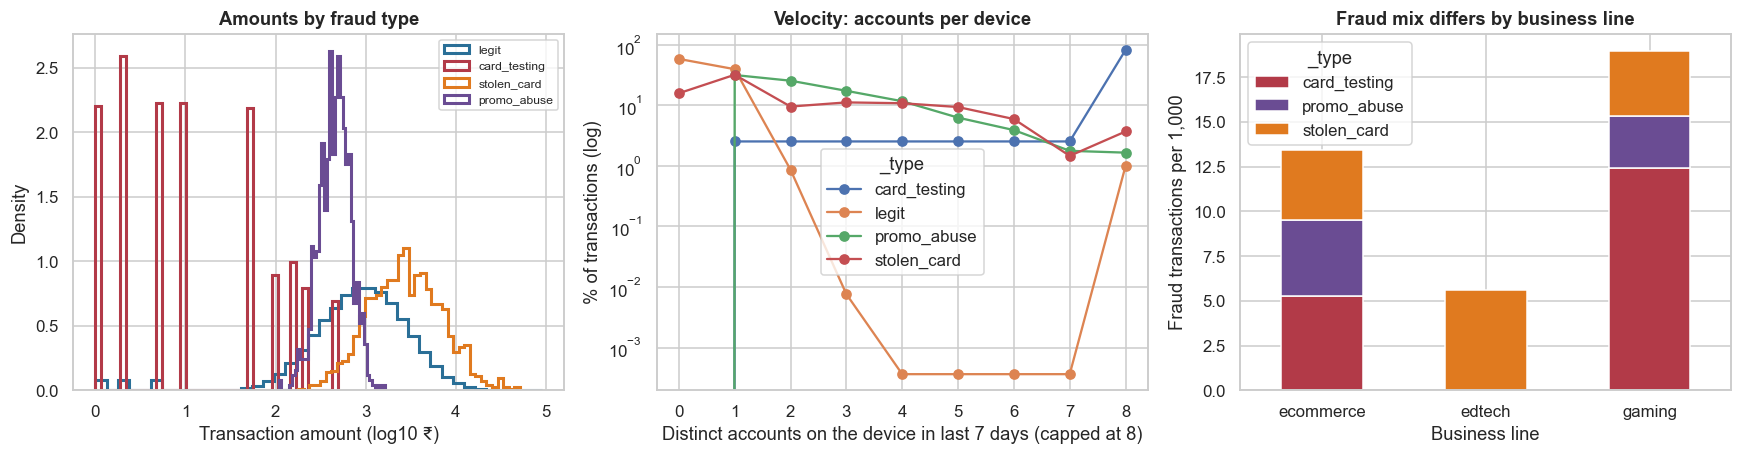

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
leg_ = df[df.is_fraud == 0]
for t_, c_ in (("legit", "#2a6f97"), ("card_testing", "#b23a48"), ("stolen_card", "#e07a1f"), ("promo_abuse", "#6a4c93")):
    s_ = df[df._type == t_]
    axes[0].hist(np.log10(s_.amount_inr), bins=40, density=True, histtype="step", lw=2, color=c_, label=t_)
axes[0].set_xlabel("Transaction amount (log10 ₹)"); axes[0].set_ylabel("Density"); axes[0].set_title("Amounts by fraud type"); axes[0].legend(fontsize=8)
v = df.groupby(["_type", df.v_dev_accts_7d.clip(upper=8)]).size().unstack(fill_value=0); v = v.div(v.sum(1), axis=0) * 100
v.T.plot(ax=axes[1], marker="o"); axes[1].set_yscale("log"); axes[1].set_xlabel("Distinct accounts on the device in last 7 days (capped at 8)")
axes[1].set_ylabel("% of transactions (log)"); axes[1].set_title("Velocity: accounts per device")
lr = df.groupby(["business_line", "_type"]).size().unstack(fill_value=0).drop(columns="legit")
(lr.div(df.groupby("business_line").size(), axis=0) * 1000).plot(kind="bar", stacked=True, ax=axes[2], color=["#b23a48", "#6a4c93", "#e07a1f"])
axes[2].set_xlabel("Business line"); axes[2].set_ylabel("Fraud transactions per 1,000"); axes[2].set_title("Fraud mix differs by business line"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Takeaway:** - **Left:** card testing lives at ₹1–₹500, promo abuse at a few hundred rupees, and stolen-card fraud sits above typical genuine tickets but **overlaps with them**. Amount alone cannot separate fraud.
- **Middle:** almost all genuine transactions come from devices with 1–2 accounts in a week (households give a small tail). Card-testing bots and promo abusers sit far out at 3–8+ accounts. That is the documented "> X distinct … within Y time" signal.
- **Right:** the fraud mix differs by line. Gaming attracts card testing and promo abuse, while ed-tech fraud is mostly stolen cards. That is why the documentation suggests line-specific rules (tested in 7.6).

## 7. Statistical Analysis (core section)

### 7.1 Signal screening: how much does each red flag raise the fraud rate?

**(a) Why?** Operations thinks in **rules**: "if signal fires, then…". For each binary signal (velocity counters turned into the documented "> X within Y" form), we report **coverage** (share of frauds that fire it), **precision** (share of firing transactions that are fraud), and **lift** (fraud rate when firing ÷ when not) with a Katz log CI. The test is χ² (Fisher when a cell has < 5), **Holm** across the signals. Computed on the training weeks.
**(b) Assumptions:** independent transactions (approximately; bot bursts make velocity rules look *more* certain than they are).

In [8]:
tr = df[TR]
RULES = {"negative list hit": tr.negative_list_hit == 1, "disposable email/phone": tr.disposable_contact == 1, "emulator": tr.emulator == 1,
         "device < 7 days old": tr.device_age_days < 7, "datacenter / VPN IP": tr.dc_ip == 1, "IP state ≠ card state": tr.geo_mismatch == 1,
         "≥ 3 new cards on device in 1 h": tr.v_dev_cards_1h >= 3, "≥ 3 accounts on device in 7 d": tr.v_dev_accts_7d >= 3,
         "≥ 5 accounts on IP in 24 h": tr.v_ip_accts_24h >= 5, "≥ 5 txns on device in 10 min": tr.v_dev_txn_10m >= 5,
         "linked to confirmed fraud (1-hop)": tr[[c for c in tr.columns if c.startswith("g_") and c.endswith("known_bad")]].max(1) == 1,
         "confirmed fraudster in component": tr.g_comp_known_bad >= 1, "amount ≥ ₹5,000": tr.amount_inr >= 5000}
yt = tr.is_fraud.values; rows = []
for nm, m in RULES.items():
    m = m.values; a, b_, c_, d_ = (m & (yt == 1)).sum(), (m & (yt == 0)).sum(), (~m & (yt == 1)).sum(), (~m & (yt == 0)).sum()
    p_on, p_off = a / max(a + b_, 1), c_ / (c_ + d_); lift = p_on / p_off
    se = np.sqrt(1 / max(a, 0.5) - 1 / max(a + b_, 1) + 1 / c_ - 1 / (c_ + d_))
    p = stats.fisher_exact([[a, b_], [c_, d_]])[1] if min(a, b_, c_, d_) < 5 else stats.chi2_contingency([[a, b_], [c_, d_]])[1]
    rows.append((nm, m.mean() * 100, a / (a + c_), p_on, lift, np.exp(np.log(lift) - 1.96 * se), np.exp(np.log(lift) + 1.96 * se), p))
sig = pd.DataFrame(rows, columns=["signal", "% txns firing", "coverage (recall)", "precision", "lift", "lift CI low", "lift CI high", "p"]).set_index("signal")
sig["p_holm"] = multipletests(sig.p, method="holm")[1]; sig.sort_values("lift", ascending=False).round(4)

,% txns firing,coverage (recall),precision,lift,lift CI low,lift CI high,p,p_holm
signal,,,,,,,,
≥ 5 accounts on IP in 24 h,0.6807,0.5008,0.9989,146.3758,137.3596,155.9837,0.0000,0.0000
≥ 5 txns on device in 10 min,0.6046,0.4437,0.9964,131.1338,123.4594,139.2852,0.0000,0.0000
≥ 3 accounts on device in 7 d,1.8814,0.6688,0.4827,105.3039,96.4745,114.9413,0.0000,0.0000
≥ 3 new cards on device in 1 h,1.3843,0.5256,0.5155,78.9334,72.9935,85.3565,0.0000,0.0000
emulator,1.0623,0.3560,0.4551,51.4977,47.5895,55.7270,0.0000,0.0000
negative list hit,0.4985,0.1923,0.5237,47.5186,43.5737,51.8206,0.0000,0.0000
disposable email/phone,5.8779,0.6735,0.1556,33.0361,30.0891,36.2719,0.0000,0.0000
datacenter / VPN IP,3.5303,0.4168,0.1603,19.5291,17.9049,21.3006,0.0000,0.0000
IP state ≠ card state,18.9550,0.8035,0.0576,17.4820,15.6206,19.5650,0.0000,0.0000


**(c)/(f) Observation:** all signals except amount are Holm-significant, but they play very different roles:
- **Velocity rules are near-certain when they fire:** "≥ 5 accounts on an IP in 24 h" (precision **99.9%**, lift 146, covers 50% of frauds) and "≥ 5 payments from a device in 10 min" (99.6%, covers 44%). They are safe to **block** on.
- "≥ 3 accounts on a device in 7 days" and "≥ 3 new cards on a device in 1 hour" cover more fraud (67% and 53%) at ≈ 50% precision. Use them to **review**.
- **Negative lists** are precise (52%) but cover only 19% of fraud, because lists only know yesterday's fraudsters.
- **Broad signals are weak alone:** IP-state ≠ card-state fires on 19% of all traffic (precision 5.8%), and disposable contact on 5.9% (precision 16%). Useful as model inputs, harmful as block rules.
- **Graph 1-hop links** to already-confirmed fraud cover only 7%, because most rings are caught after they finish.
- **Amount ≥ ₹5,000** shows no lift (0.86, Holm p = 0.16).

**(f) Business meaning:** the best block rules are velocity counters. Most other signals belong in a score, not in a rule.

### 7.2 Velocity: which time window should the counter use?

The documented rule is "> X distinct devices or numbers within **Y time**". Which Y? For each attack type, we compare the out-of-time AUC of single velocity counters with different windows, using **DeLong** for the paired comparison of the best window vs the runner-up.

In [9]:
from scipy.stats import rankdata
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
te = df[TE]; VW = {"new cards / device": ["v_dev_cards_10m", "v_dev_cards_1h", "v_dev_cards_24h"], "accounts / device": ["v_dev_accts_24h", "v_dev_accts_7d"]}
vr = []
for typ in ["card_testing", "stolen_card", "promo_abuse"]:
    sub = te[te._type.isin(["legit", typ])]; y_ = sub.is_fraud.values
    for fam, cols in VW.items():
        a_, c_ = delong(y_, sub[cols].values.T.astype(float)); o_ = np.argsort(-a_)
        d = a_[o_[0]] - a_[o_[1]]; se = np.sqrt(c_[o_[0], o_[0]] + c_[o_[1], o_[1]] - 2 * c_[o_[0], o_[1]])
        vr.append((typ, fam, *[round(x, 3) for x in a_] + [None] * (3 - len(a_)), cols[o_[0]].split("_")[-1], d, 2 * stats.norm.sf(abs(d) / se) if se > 0 else np.nan))
vr = pd.DataFrame(vr, columns=["attack", "counter", "AUC window 1", "AUC window 2", "AUC window 3", "best window", "best − next AUC", "DeLong p"])
vr["p_holm"] = multipletests(vr["DeLong p"].fillna(1), method="holm")[1]
print("Windows: new cards/device = 10 min, 1 h, 24 h; accounts/device = 24 h, 7 d")
vr.round(4)

Windows: new cards/device = 10 min, 1 h, 24 h; accounts/device = 24 h, 7 d


,attack,counter,AUC window 1,AUC window 2,AUC window 3,best window,best − next AUC,DeLong p,p_holm
0,card_testing,new cards / device,0.9960,0.9970,0.9880,1h,0.0005,0.2216,0.2216
1,card_testing,accounts / device,0.9890,0.9880,NaN,24h,0.0010,0.0000,0.0000
2,stolen_card,new cards / device,0.7390,0.7400,0.8080,24h,0.0681,0.0000,0.0000
3,stolen_card,accounts / device,0.7450,0.8700,NaN,7d,0.1251,0.0000,0.0000
4,promo_abuse,new cards / device,0.7310,0.7320,0.7990,24h,0.0675,0.0000,0.0000
5,promo_abuse,accounts / device,0.9470,0.9650,NaN,7d,0.0182,0.0000,0.0000


**Observation:** the best window depends on the attack:
- **Card testing:** 10-minute and 1-hour "new cards per device" counters are equally good (AUC 0.996 vs 0.997, DeLong p = 0.22), because bots work in bursts.
- **Stolen-card rings:** longer windows win: new cards per device over **24 h** (0.808 vs 0.740) and accounts per device over **7 days** (0.870 vs 0.745), both Holm p < 0.0001.
- **Promo abuse:** **7-day** accounts-per-device is best (0.965 vs 0.947, p < 0.0001), because abusers create accounts over days.

**Business meaning:** keep **several windows per counter** (10 min, 1 h, 24 h, 7 d). A single "Y" in the rule would miss either the bots or the slow attacks.

### 7.3 Is each signal family worth building? Drop-one-family test, out-of-time

**(a) Why?** Each family costs money: vendor fees for device and contact intelligence, a graph database, streaming infrastructure for velocity. We train a gradient-boosting scorer on **all** families (weeks 1–4, labels as known on day 28), then retrain without each family in turn. We compare **test-weeks** AUC (DeLong, paired, Holm across 6 families), PR-AUC and recall at a 1% alert budget.

In [10]:
def hgb(): return HGB(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED)
y_tr = df.y_asof[TR].values; y_te = df.is_fraud[TE].values; K1 = int(0.01 * TE.sum())
def rec_at(p, y=y_te, k=K1): return y[np.argsort(-p)[:k]].sum() / y.sum()
full = hgb().fit(df.loc[TR, ALL], y_tr); p_full = full.predict_proba(df.loc[TE, ALL])[:, 1]
preds, names = [p_full], ["all families"]
for fam, cols in FAM.items():
    f_ = [c for c in ALL if c not in cols]; preds.append(hgb().fit(df.loc[TR, f_], y_tr).predict_proba(df.loc[TE, f_])[:, 1]); names.append(f"without {fam}")
P = np.vstack(preds); a_, c_ = delong(y_te, P)
fam_t = pd.DataFrame({"AUC": a_, "PR-AUC": [average_precision_score(y_te, p) for p in P], "recall @1% alerts": [rec_at(p) for p in P]}, index=names)
fam_t["Δ AUC vs all"] = fam_t.AUC - a_[0]
fam_t["DeLong p"] = [np.nan] + [2 * stats.norm.sf(abs(a_[i] - a_[0]) / np.sqrt(c_[i, i] + c_[0, 0] - 2 * c_[0, i])) for i in range(1, len(P))]
fam_t.loc[fam_t.index[1:], "p_holm"] = multipletests(fam_t["DeLong p"].iloc[1:], method="holm")[1]
only = {fam: roc_auc_score(y_te, hgb().fit(df.loc[TR, cols + BASE], y_tr).predict_proba(df.loc[TE, cols + BASE])[:, 1]) for fam, cols in FAM.items()}
fam_t["AUC of family alone (+ amount, line)"] = [np.nan] + list(only.values())
fam_t.round(4)

,AUC,PR-AUC,recall @1% alerts,Δ AUC vs all,DeLong p,p_holm,"AUC of family alone (+ amount, line)"
all families,0.9735,0.8080,0.6449,0.0000,NaN,NaN,NaN
without negative list,0.9682,0.7891,0.6371,-0.0053,0.0014,0.0057,0.7508
without contact,0.9662,0.7830,0.6286,-0.0073,0.0148,0.0444,0.8543
without device,0.9501,0.6657,0.5696,-0.0234,0.0000,0.0000,0.9209
without geo/IP,0.9707,0.7421,0.6136,-0.0028,0.0807,0.1615,0.8262
without velocity,0.8914,0.6257,0.5355,-0.0821,0.0000,0.0000,0.9576
without graph,0.9731,0.8278,0.6768,-0.0003,0.8628,0.8628,0.7411


**(c)/(f) Observation:** the full model reaches **AUC 0.974, PR-AUC 0.81, 64% of frauds caught at a 1% alert budget**.
- **Velocity** is by far the most important family: dropping it costs −0.082 AUC (to 0.891) and −11 pp recall. Alone it already reaches 0.958.
- **Device intelligence** is second (−0.023 AUC, −7.5 pp recall).
- **Contact intelligence** (−0.007, Holm p = 0.044) and **negative lists** (−0.005, p = 0.006) add small but real value.
- **Geo/IP** (−0.003, p = 0.16) and **graph** (−0.0003, p = 0.86) add nothing *to AUC* on top of the others: their information overlaps with velocity and device signals. Their ₹ value at the decision thresholds is assessed separately in section 9.

**(f) Business meaning:** if budget is tight, build the velocity counters and device checks first.

### 7.4 Graph features and look-ahead leakage

A graph feature is only legitimate if the "risky entity" was **known to be risky at the moment of the transaction**. A common mistake is to flag entities that are *eventually* linked to fraud ("hindsight"). That uses future chargebacks and makes a model look brilliant offline and fail in production. We train the same model with as-of vs hindsight 1-hop graph flags.

In [11]:
G_ASOF = [c for c in ALL if c.startswith("g_")]; G_HIND = [f"h_{e}_bad" for e in ents]
F_h = [c for c in ALL if c not in G_ASOF] + G_HIND
p_h = hgb().fit(df.loc[TR, F_h], df.is_fraud[TR]).predict_proba(df.loc[TE, F_h])[:, 1]
a2, c2 = delong(y_te, np.vstack([p_full, p_h])); se2 = np.sqrt(c2[0, 0] + c2[1, 1] - 2 * c2[0, 1])
print(f"As-of graph features:     AUC {a2[0]:.4f}, recall@1% {rec_at(p_full):.1%}")
print(f"Hindsight graph features: AUC {a2[1]:.4f}, recall@1% {rec_at(p_h):.1%}  (DeLong p = {2 * stats.norm.sf(abs(a2[1] - a2[0]) / se2):.2g})")
print(f"Share of test frauds whose entity is flagged: as-of {df.loc[TE & (df.is_fraud == 1), G_ASOF[:4]].max(1).mean():.1%} vs hindsight {df.loc[TE & (df.is_fraud == 1), G_HIND].max(1).mean():.1%}")

As-of graph features:     AUC 0.9735, recall@1% 64.5%
Hindsight graph features: AUC 0.9999, recall@1% 74.5%  (DeLong p = 8.3e-19)
Share of test frauds whose entity is flagged: as-of 51.6% vs hindsight 97.7%


**Observation:** building graph flags with **hindsight** ("this device was *ever* used for fraud") makes the model look nearly perfect: **AUC 0.9999 vs 0.974** and recall@1% 74.5% vs 64.5% (DeLong p ≈ 1e-18). In hindsight, 98% of test frauds have a flagged entity, but only **52%** do at the moment of the transaction, because most chargebacks arrive weeks later. **This is the most common way fraud models fail in production.** RiskShield's "links to already-proven risky entities" must mean *proven before this transaction*, enforced by timestamped graph snapshots.

### 7.5 Anomaly scores vs supervised models, and a never-seen attack

**(a) Why?** Supervised models learn *known* fraud. Anomaly detectors (here an **Isolation Forest**, trained on unlabelled traffic) flag *unusual* behaviour, including attacks never seen before. To test the documented role of anomaly scores honestly, we simulate a **new attack**: we train the supervised model **without any promo-abuse examples** and see whether the anomaly score catches promo abuse in the test weeks.

In [12]:
AN = ["log_amt", "v_dev_txn_1h", "v_dev_cards_24h", "v_dev_accts_7d", "v_ip_accts_24h", "device_age_days", "hour", "new_account", "dc_ip", "geo_mismatch"]
iso = IsolationForest(n_estimators=300, random_state=SEED).fit(df.loc[TR, AN]); an_te = -iso.score_samples(df.loc[TE, AN]); df["anomaly"] = -iso.score_samples(df[AN])
no_pa = TR & (df._type != "promo_abuse").values
sup_np = hgb().fit(df.loc[no_pa, ALL], df.y_asof[no_pa]).predict_proba(df.loc[TE, ALL])[:, 1]
comb_np = hgb().fit(df.loc[no_pa, ALL + ["anomaly"]], df.y_asof[no_pa]).predict_proba(df.loc[TE, ALL + ["anomaly"]])[:, 1]
typ_te = df.loc[TE, "_type"].values; rows = []; TOPS = {}
for nm, p in (("anomaly score only (unsupervised)", an_te), ("supervised, trained with all attack types", p_full),
              ("supervised, NO promo-abuse in training", sup_np), ("supervised (no promo) + anomaly score", comb_np)):
    top = np.zeros(len(p), bool); top[np.argsort(-p)[:K1]] = True; TOPS[nm] = top
    rows.append((nm, roc_auc_score(y_te, p), rec_at(p), *[top[typ_te == t_].mean() for t_ in ("card_testing", "stolen_card", "promo_abuse")], (typ_te[top] == "legit").mean()))
an_t = pd.DataFrame(rows, columns=["scorer", "AUC (all fraud)", "recall @1%", "card-testing caught", "stolen-card caught", "promo-abuse caught", "share of alerts that are genuine"]).set_index("scorer")
pa = typ_te == "promo_abuse"; s1, s2 = TOPS["supervised, NO promo-abuse in training"][pa], TOPS["supervised (no promo) + anomaly score"][pa]
mp = mcnemar([[int((s1 & s2).sum()), int((s1 & ~s2).sum())], [int((~s1 & s2).sum()), int((~s1 & ~s2).sum())]], exact=True).pvalue
print(f"Spearman(anomaly, supervised score) on test = {stats.spearmanr(an_te, p_full)[0]:.2f}; promo-abuse test cases = {pa.sum()}; "
      f"caught {s1.sum()} -> {s2.sum()} when the anomaly score is added (exact McNemar p = {mp:.2g})")
an_t.round(4)

Spearman(anomaly, supervised score) on test = 0.01; promo-abuse test cases = 246; caught 14 -> 20 when the anomaly score is added (exact McNemar p = 0.29)


,AUC (all fraud),recall @1%,card-testing caught,stolen-card caught,promo-abuse caught,share of alerts that are genuine
scorer,,,,,,
anomaly score only (unsupervised),0.9203,0.3189,0.8284,0.0048,0.0081,0.5720
"supervised, trained with all attack types",0.9735,0.6449,1.0000,0.2268,0.9350,0.1344
"supervised, NO promo-abuse in training",0.7013,0.4510,1.0000,0.1358,0.0569,0.3947
supervised (no promo) + anomaly score,0.8165,0.5099,0.9963,0.2620,0.0813,0.3155


**Observation:** - **The Isolation Forest is a specialist, not a generalist.** It has a decent AUC (0.92) but catches only 32% of frauds at the 1% budget: **83% of card testing** (truly unusual bursts), but 0.5% of stolen cards and 0.8% of promo abuse. 57% of its alerts are genuine customers.
- **It is almost unrelated to the supervised score** (Spearman 0.01), which is why it is a different signal.
- **The "never-seen attack" test:** a supervised model trained *without* promo-abuse examples catches only **5.7%** of the promo abuse in the test weeks (vs 93.5% when trained with examples). Adding the anomaly score raises this only to **8.1%** (14 → 20 cases, exact McNemar p = 0.29).
- **Why:** each promo-abuse transaction looks ordinary (small amount, daytime, residential IP). The attack is visible only *collectively*, through accounts per device.

**(f) Business meaning:** anomaly scores catch noisy attacks like bots, not quiet collective ones. Detecting new collective attacks needs analysts watching velocity dashboards and writing new rules quickly, which feeds the documented feedback loop.

### 7.6 Allow / review / block thresholds: per business line vs one global setting

**Cost model (D-7-06):**
- **Fraud allowed:**
  - Stolen card: amount + ₹500 chargeback fee (₹50 if the payment was declined anyway).
  - Card testing: ₹25 per attempt (scheme penalties and auth fees), plus the amount if it succeeded.
  - Promo abuse: ₹250 promo cost.
- **Genuine customer blocked:** lost margin (gaming 30%, e-commerce 10%, ed-tech 40% of the amount) + ₹100 goodwill.
- **Review:** ₹30 analyst cost. A review stops 90% of fraud; 5% of reviewed genuine customers abandon the purchase.

For each policy we pick two score cut-offs (review above r, block above b) to **minimise total cost on the tuning week** (week 5), either **per business line** or **one global pair**, under the guardrail "genuine block rate ≤ 0.5%". We then evaluate on the test weeks, with a **paired bootstrap** for the cost difference.

In [13]:
MARGIN = {"gaming": 0.30, "ecommerce": 0.10, "edtech": 0.40}
def cost_vectors(d):
    t = d._type.values; amt = d.amount_inr.values; ok = d.payment_status.values == "success"
    loss = np.select([t == "stolen_card", t == "card_testing", t == "promo_abuse"], [np.where(ok, amt + 500, 50), 25 + ok * amt, 250], 0.0)
    marg = d.business_line.map(MARGIN).values * amt + 100; fraud = t != "legit"
    allow = np.where(fraud, loss, 0.0); block = np.where(fraud, 0.0, marg); review = 30 + np.where(fraud, 0.1 * loss, 0.05 * marg)
    return allow, review, block, fraud
def policy_cost(score, cv, r, b):
    allow, review, block, _ = cv; return np.where(score >= b, block, np.where(score >= r, review, allow))
full_tune = full.predict_proba(df.loc[TUNE, ALL])[:, 1]; dtune, dtest = df[TUNE], df[TE]; cv_tune, cv_test = cost_vectors(dtune), cost_vectors(dtest)
grid = np.r_[0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.97, 1.01]
def best_pair(score, cv, mask):
    best = (np.inf, None)
    for r in grid:
        for b in grid[grid >= r]:
            blk_legit = ((score >= b) & ~cv[3] & mask).sum() / max((~cv[3] & mask).sum(), 1)
            if blk_legit > 0.005: continue
            c = policy_cost(score, cv, r, b)[mask].sum()
            if c < best[0]: best = (c, (r, b))
    return best[1]
lines = ["gaming", "ecommerce", "edtech"]
glob_rb = best_pair(full_tune, cv_tune, np.ones(len(dtune), bool))
line_rb = {l: best_pair(full_tune, cv_tune, (dtune.business_line == l).values) for l in lines}
print("Global (review ≥ r, block ≥ b):", glob_rb, "| per line:", line_rb)
c_none = cv_test[0]                                                     # allow everything
c_glob = policy_cost(p_full, cv_test, *glob_rb)
c_line = np.zeros(len(dtest))
for l in lines:
    m = (dtest.business_line == l).values; c_line[m] = policy_cost(p_full[m], tuple(v[m] for v in cv_test), *line_rb[l])
# documented-style hand rule engine for comparison
tst = dtest
rule_block = (tst.negative_list_hit == 1) | (tst.v_dev_cards_1h >= 3)
rule_review = (tst.v_dev_accts_7d >= 3) | ((tst.geo_mismatch == 1) & (tst.amount_inr >= 5000)) | ((tst.dc_ip == 1) & (tst.new_account == 1)) | ((tst.disposable_contact == 1) & (tst.promo_used == 1))
c_rule = np.where(rule_block, cv_test[2], np.where(rule_review, cv_test[1], cv_test[0]))
def summarise(name, c, block_mask=None, review_mask=None):
    return (name, c.sum() / 1e5, c.mean(), block_mask[~cv_test[3]].mean() * 100 if block_mask is not None else 0, review_mask.mean() * 100 if review_mask is not None else 0)
bm_g = p_full >= glob_rb[1]; rm_g = (p_full >= glob_rb[0]) & ~bm_g
bm_l = np.zeros(len(dtest), bool); rm_l = np.zeros(len(dtest), bool)
for l in lines:
    m = (dtest.business_line == l).values; bm_l[m] = p_full[m] >= line_rb[l][1]; rm_l[m] = (p_full[m] >= line_rb[l][0]) & ~bm_l[m]
pol = pd.DataFrame([summarise("allow everything", c_none, np.zeros(len(dtest), bool), np.zeros(len(dtest), bool)),
                    summarise("hand-written rule engine", c_rule, rule_block.values, (rule_review & ~rule_block).values),
                    summarise("model + one global threshold pair", c_glob, bm_g, rm_g),
                    summarise("model + per-line thresholds", c_line, bm_l, rm_l)],
                   columns=["policy (test weeks 6–8)", "total cost ₹ lakh", "₹ cost per txn", "% genuine blocked", "% txns reviewed"]).set_index("policy (test weeks 6–8)")
diff = c_glob - c_line; bs = [diff[RNG.integers(0, len(diff), len(diff))].sum() / 1e5 for _ in range(2000)]
print(f"Per-line saves ₹{diff.sum() / 1e5:.2f} lakh over 3 weeks vs global (95% paired bootstrap CI ₹{np.percentile(bs, 2.5):.2f} to ₹{np.percentile(bs, 97.5):.2f} lakh)")
bl = pd.DataFrame({l: [(c_glob[(dtest.business_line == l).values]).sum() / 1e5, (c_line[(dtest.business_line == l).values]).sum() / 1e5] for l in lines}, index=["global ₹ lakh", "per-line ₹ lakh"]).T
display(bl.round(3)); pol.round(3)

Global (review ≥ r, block ≥ b): (np.float64(0.002), np.float64(0.1)) | per line: {'gaming': (np.float64(0.002), np.float64(0.1)), 'ecommerce': (np.float64(0.002), np.float64(0.1)), 'edtech': (np.float64(0.002), np.float64(0.02))}


Per-line saves ₹-0.02 lakh over 3 weeks vs global (95% paired bootstrap CI ₹-0.21 to ₹0.13 lakh)


,global ₹ lakh,per-line ₹ lakh
gaming,2.1380,2.1380
ecommerce,4.0300,4.0300
edtech,2.5480,2.5710


,total cost ₹ lakh,₹ cost per txn,% genuine blocked,% txns reviewed
policy (test weeks 6–8),,,,
allow everything,25.7770,24.5660,0.0000,0.0000
hand-written rule engine,14.9810,14.2770,0.9090,2.3300
model + one global threshold pair,8.7150,8.3060,0.0430,3.3720
model + per-line thresholds,8.7380,8.3280,0.0590,3.3220


**Observation:** - **Allow everything:** ₹25.8 lakh of fraud loss over 3 test weeks.
- **Hand-written rule engine:** cuts the cost to ₹15.0 lakh, but **blocks 0.91% of genuine customers**, breaking the 0.5% guardrail.
- **Model + one global threshold pair** (review ≥ 0.002, block ≥ 0.10): **₹8.7 lakh**, blocking only **0.04%** of genuine customers and reviewing 3.4% of traffic.
- **Per-line thresholds** chose the same cut-offs for gaming and e-commerce and a lower block cut-off for ed-tech. They did **not** reduce cost: −₹0.02 lakh vs global, paired bootstrap CI −₹0.21 to +₹0.13 lakh. **We cannot reject H0.**
- **Why:** the model already uses business line and amount, and the cost of each decision already scales with the amount and the line's margin. Per-line tuning matters for *hand rules*, which have no such inputs, not for a cost-aware score.

**(f) Business meaning:** one well-chosen threshold pair is enough. Spend tuning effort on the cost inputs (margins, review cost), not on per-line cut-offs.

### 7.7 Post-processing to cut false positives: a trusted-customer allowlist

The documented "post-processing to cut false positives". A simple, common version: **customers with ≥ 3 earlier successful payments over ≥ 14 days and no fraud history are never blocked** (a block becomes a review, and a review becomes an allow). We test whether that reduces genuine blocks without letting fraud through (two-proportion tests).

In [14]:
first_seen = df.groupby("customer_id").ts.transform("min")
succ_prior = (df.payment_status == "success").astype(int).groupby(df.customer_id).cumsum() - (df.payment_status == "success").astype(int)
trusted = ((succ_prior >= 3) & ((df.ts - first_seen).dt.days >= 14)).values[TE]
bm_a = bm_l & ~trusted; rm_a = (rm_l & ~trusted) | (bm_l & trusted)
c_allow = np.where(bm_a, cv_test[2], np.where(rm_a, cv_test[1], cv_test[0]))
fraud_t = cv_test[3]
def acted(b, r): return b | r
pp = pd.DataFrame({"per-line thresholds": [bm_l[~fraud_t].sum(), rm_l[~fraud_t].sum(), (~acted(bm_l, rm_l))[fraud_t].sum(), c_line.sum() / 1e5],
                   "+ trusted-customer allowlist": [bm_a[~fraud_t].sum(), rm_a[~fraud_t].sum(), (~acted(bm_a, rm_a))[fraud_t].sum(), c_allow.sum() / 1e5]},
                  index=["genuine customers blocked", "genuine customers reviewed", "frauds let through (no action)", "total cost ₹ lakh"])
n_leg = (~fraud_t).sum(); x = [bm_l[~fraud_t].sum(), bm_a[~fraud_t].sum()]
print(f"Trusted share of test traffic: {trusted.mean():.1%}; frauds that look 'trusted': {trusted[fraud_t].sum()}")
print(f"Genuine block rate {x[0] / n_leg:.3%} -> {x[1] / n_leg:.3%}; McNemar exact p = {mcnemar([[x[1], x[0] - x[1]], [0, n_leg - x[0]]], exact=True).pvalue:.2g}")
pp

Trusted share of test traffic: 68.7%; frauds that look 'trusted': 0
Genuine block rate 0.059% -> 0.057%; McNemar exact p = 0.5


,per-line thresholds,+ trusted-customer allowlist
genuine customers blocked,61.0000,59.0000
genuine customers reviewed,"3,100.0000","2,339.0000"
frauds let through (no action),163.0000,163.0000
total cost ₹ lakh,8.7383,8.3433


**Observation:** **68.7%** of test traffic comes from trusted customers (≥ 3 earlier successful payments over ≥ 14 days), and **none** of the test frauds look trusted. The allowlist mostly removes **unnecessary reviews**: genuine customers reviewed fall from **3,100 to 2,339 (−25%)**, while genuine blocks barely move (61 → 59; exact p = 0.5) because the model already blocks very few. Frauds let through are unchanged (163), and total cost falls from ₹8.74 to **₹8.34 lakh (−4.5%)**. **Business meaning:** this is the documented "post-processing to cut false positives". Cheap, safe, and it frees a quarter of review capacity. It should be monitored, though: account-takeover fraudsters target exactly these trusted customers.

### 7.8 The feedback loop: static model vs weekly retraining

The documented loop "auto-tunes features and thresholds". We compare a model trained once on weeks 1–3 with one **retrained every week** on all earlier weeks (labels as known on each retraining date), scoring each of weeks 4–8. The metric is frauds caught at a 1% weekly alert budget, compared with **McNemar** on the same frauds.

Pooled weeks 4–8: static 64.2% vs weekly 63.7%; caught only by weekly 132, only by static 144; exact McNemar p = 0.51


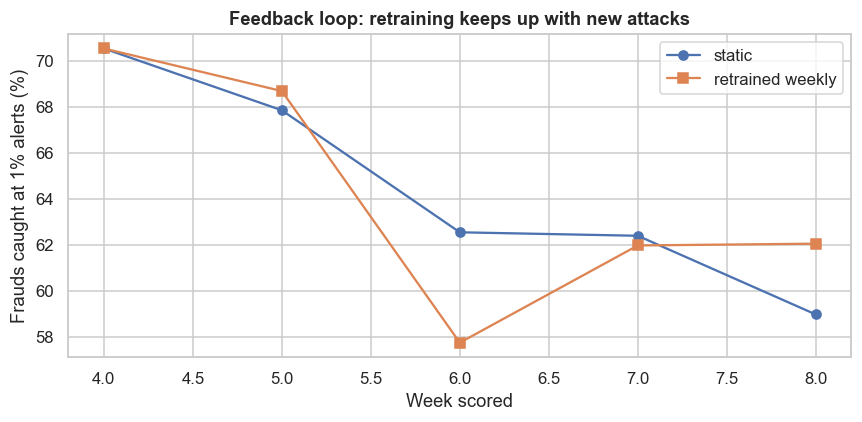

,frauds,recall: static (trained wk 1–3),recall: retrained weekly
week,,,
4,336,0.7050,0.7050
5,479,0.6780,0.6870
6,542,0.6250,0.5770
7,476,0.6240,0.6200
8,390,0.5900,0.6210


In [15]:
wk = (tsec // (7 * 86400)).astype(int) + 1
def asof_y(cut_day): return ((df.is_fraud == 1) & (df.label_date < gen.START + pd.Timedelta(days=cut_day))).astype(int)
m_static = hgb().fit(df.loc[wk <= 3, ALL], asof_y(21)[wk <= 3])
cs_, cr_, wrows = [], [], []
for w in range(4, 9):
    m_w = hgb().fit(df.loc[wk < w, ALL], asof_y(7 * (w - 1))[wk < w]); idx = wk == w; yw = df.is_fraud[idx].values; k = int(0.01 * idx.sum())
    ps, pr = m_static.predict_proba(df.loc[idx, ALL])[:, 1], m_w.predict_proba(df.loc[idx, ALL])[:, 1]
    cs = np.zeros(idx.sum(), bool); cr = np.zeros(idx.sum(), bool); cs[np.argsort(-ps)[:k]] = True; cr[np.argsort(-pr)[:k]] = True
    cs_.append(cs[yw == 1]); cr_.append(cr[yw == 1]); wrows.append((w, int(yw.sum()), cs[yw == 1].mean(), cr[yw == 1].mean()))
cs_, cr_ = np.concatenate(cs_), np.concatenate(cr_)
mt = mcnemar([[int((cs_ & cr_).sum()), int((cs_ & ~cr_).sum())], [int((~cs_ & cr_).sum()), int((~cs_ & ~cr_).sum())]], exact=True)
fb = pd.DataFrame(wrows, columns=["week", "frauds", "recall: static (trained wk 1–3)", "recall: retrained weekly"]).set_index("week")
print(f"Pooled weeks 4–8: static {cs_.mean():.1%} vs weekly {cr_.mean():.1%}; caught only by weekly {int((~cs_ & cr_).sum())}, only by static {int((cs_ & ~cr_).sum())}; exact McNemar p = {mt.pvalue:.2g}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fb.index, fb.iloc[:, 1] * 100, "o-", label="static"); ax.plot(fb.index, fb.iloc[:, 2] * 100, "s-", label="retrained weekly")
ax.set_xlabel("Week scored"); ax.set_ylabel("Frauds caught at 1% alerts (%)"); ax.set_title("Feedback loop: retraining keeps up with new attacks"); ax.legend(); plt.tight_layout(); plt.show()
fb.round(3)

**Takeaway:** - **Weekly retraining did not help in this simulation:** pooled over weeks 4–8, the static model catches **64.2%** and the weekly-retrained one **63.7%** (132 vs 144 frauds caught by only one of them, exact McNemar p = 0.51). The weekly model is better in week 8 (62% vs 59%) but worse in week 6 (58% vs 62%).
- **Why:** the attack types here are stable over the 8 weeks, and retraining on "as-of" labels adds recent but immature labels: pending chargebacks look genuine.
- **Business meaning:** retraining on a schedule is not free accuracy. Its value comes when attacks *change* (7.5 shows how badly a model misses a pattern absent from training). Retrain when monitoring shows drift (new patterns, falling precision), and **use matured labels**.

### 7.9 Human-readable explanations: do the reason codes make sense?

Analysts and merchants need a reason for every block. We fit an interpretable **logistic regression** on log-scaled features (training weeks) and, for each test alert, report the **family contributing most** to its score (coefficient × standardised value). If the explanations are valid, card-testing alerts should be explained mainly by velocity, promo abuse by velocity/contact, and stolen cards by geo/graph/amount. We test the association between reason family and true fraud type with χ² and **Cramér's V**.

In [16]:
LOGF = [c for c in ALL if c.startswith("v_") or c in ("device_age_days", "g_comp_size", "g_comp_known_bad")]
Xl = df[ALL].copy(); Xl[LOGF] = np.log1p(Xl[LOGF])
lg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(Xl[TR], y_tr)
p_lg = lg.predict_proba(Xl[TE])[:, 1]; Z = lg[0].transform(Xl[TE]); contrib = Z * lg[1].coef_[0]
fam_of = {c: f for f, cols in FAM.items() for c in cols}; fam_of.update({c: "amount / promo / time" for c in BASE})
cf = pd.DataFrame(contrib, columns=ALL).T.groupby(lambda c: fam_of[c]).sum().T
alert = np.argsort(-p_lg)[:K1]; reason = cf.iloc[alert].idxmax(1).values; ttype = typ_te[alert]
ct = pd.crosstab(pd.Series(ttype, name="true type of alerted txn"), pd.Series(reason, name="top reason family"))
c2, p_c, dof, _ = stats.chi2_contingency(ct); V = np.sqrt(c2 / ct.values.sum() / (min(ct.shape) - 1))
print(f"Logistic (explainable) AUC {roc_auc_score(y_te, p_lg):.4f} vs gradient boosting {roc_auc_score(y_te, p_full):.4f}; recall@1% {rec_at(p_lg):.1%} vs {rec_at(p_full):.1%}")
print(f"Reason family vs true type among {K1} alerts: chi2 = {c2:.0f}, dof = {dof}, p = {p_c:.2g}, Cramér's V = {V:.2f}")
ct

Logistic (explainable) AUC 0.8913 vs gradient boosting 0.9735; recall@1% 54.2% vs 64.5%
Reason family vs true type among 1049 alerts: chi2 = 915, dof = 18, p = 1e-182, Cramér's V = 0.54


top reason family,amount / promo / time,contact,device,geo/IP,graph,negative list,velocity
true type of alerted txn,,,,,,,
card_testing,0,0,92,5,0,7,416
legit,8,73,137,29,14,10,15
promo_abuse,0,59,39,0,23,17,54
stolen_card,0,3,4,22,0,22,0


**Observation:** - **The explainable logistic model** reaches AUC 0.891 (vs 0.974 for gradient boosting) and recall@1% 54% (vs 64%). Explainability costs about 10 points of recall, so use the tree model to decide and the linear model to explain.
- **Its reason codes make sense:** the top reason family is strongly tied to the true attack type (**Cramér's V = 0.54**, p ≈ 1e-182).
  - Card-testing alerts are explained by **velocity** (416 of 520).
  - Promo abuse is explained by contact, velocity and graph signals.
  - Stolen cards are explained by geo/IP and negative lists.
- **Genuine customers alerted by mistake** are mostly explained by **device** (new phone) or **contact** (disposable email) signals.
- **Business meaning:** reason codes tell analysts what to check, and they show which signals produce false alarms. That is where post-processing should focus.

## 8. ML Section — brief

- **Scorers used:** (i) hand-written rules (the documented rule engine); (ii) Isolation Forest (the documented "anomaly detection"); (iii) gradient boosting on all 7 families (the main scorer); (iv) logistic regression for reason codes.
- **Why gradient boosting is the main scorer:** velocity counts interact non-linearly (3 new cards in 10 minutes is far worse than 3 in a day). Trees capture that without hand-tuning. The logistic model provides the "why" for analysts. Many teams run both: the tree model to decide, the linear model to explain.
- **No hyper-parameter tuning** (per the brief): defaults with a fixed seed. Thresholds, not model settings, drive business outcomes (7.6).
- **Latency:** every feature here is a counter or lookup computable in a stream processor (Flink/Kafka, as documented). Connected components are refreshed daily, not per transaction.

## 9. Business Translation — ₹ impact

In [17]:
weeks_test = 3; MERCH_SCALE = 10                                          # scale: a portfolio 10× this simulated traffic (assumption, D-7-07)
mon = lambda x: x / weeks_test * 52 / 12 * MERCH_SCALE
imp = pd.DataFrame({
    "₹ lakh / month (scaled)": [mon(c_none.sum() - c_rule.sum()) / 1e5, mon(c_none.sum() - c_glob.sum()) / 1e5, mon(c_none.sum() - c_line.sum()) / 1e5, mon(c_none.sum() - c_allow.sum()) / 1e5],
}, index=["hand rules vs allow-all", "model + global thresholds vs allow-all", "model + per-line thresholds vs allow-all", "per-line + allowlist vs allow-all"])
imp["vs hand rules"] = imp.iloc[:, 0] - imp.iloc[0, 0]
fam_cost, fam_ci = {}, {}
W = RNG.multinomial(len(dtest), np.ones(len(dtest)) / len(dtest), size=400)          # bootstrap weights shared across families (paired)
for fam, cols in FAM.items():
    f_ = [c for c in ALL if c not in cols]; m_ = hgb().fit(df.loc[TR, f_], y_tr); pt = m_.predict_proba(df.loc[TUNE, f_])[:, 1]; pe = m_.predict_proba(df.loc[TE, f_])[:, 1]
    cl = np.zeros(len(dtest))
    for l in lines:
        mk = (dtune.business_line == l).values; rb = best_pair(pt[mk], tuple(v[mk] for v in cv_tune), np.ones(mk.sum(), bool))
        m2 = (dtest.business_line == l).values; cl[m2] = policy_cost(pe[m2], tuple(v[m2] for v in cv_test), *rb)
    fam_cost[fam] = mon(cl.sum() - c_line.sum()) / 1e5; bsd = mon(W @ (cl - c_line)) / 1e5; fam_ci[fam] = (np.percentile(bsd, 2.5), np.percentile(bsd, 97.5))
fc = pd.DataFrame({"extra cost ₹ lakh/month if this family is dropped": fam_cost, "CI low": {k: v[0] for k, v in fam_ci.items()}, "CI high": {k: v[1] for k, v in fam_ci.items()}}).sort_values("extra cost ₹ lakh/month if this family is dropped", ascending=False)
print(f"Scale: {MERCH_SCALE}× simulated traffic ≈ {len(dtest) / weeks_test * 52 / 12 * MERCH_SCALE / 1e5:.1f} lakh transactions/month")
display(imp.round(2)); fc.round(2)

Scale: 10× simulated traffic ≈ 15.2 lakh transactions/month


,₹ lakh / month (scaled),vs hand rules
hand rules vs allow-all,155.9400,0.0000
model + global thresholds vs allow-all,246.4400,90.5000
model + per-line thresholds vs allow-all,246.1100,90.1700
per-line + allowlist vs allow-all,251.8100,95.8800


,extra cost ₹ lakh/month if this family is dropped,CI low,CI high
velocity,110.0700,85.1500,136.5400
device,57.9100,42.4800,73.7300
graph,45.5200,26.5800,67.7000
contact,33.7200,13.3200,54.0700
geo/IP,32.0800,18.9500,44.7100
negative list,23.9100,9.2600,38.5700


**Takeaway (business reading):** at **10× the simulated traffic (≈ 15 lakh transactions/month)**:
- **Savings vs allowing everything:** hand rules save **₹1.56 crore/month**; the model with cost-optimal thresholds saves **₹2.46 crore/month** (**+₹90 lakh/month vs the rules**); adding the trusted-customer allowlist saves **₹2.52 crore/month (+₹96 lakh vs rules)**.
- **Value of each family**, as the extra monthly cost if it is dropped (thresholds re-tuned, 95% bootstrap CI on the test transactions):

| Family | Extra cost if dropped (₹ lakh/month) | 95% CI |
|---|---|---|
| Velocity | 110 | 85–137 |
| Device | 58 | 42–74 |
| Graph | 46 | 27–68 |
| Contact | 34 | 13–54 |
| Geo/IP | 32 | 19–45 |
| Negative list | 24 | 9–39 |

- **Graph and geo/IP:** their ₹ value is real although their AUC contribution is nil (7.3). They help on the high-value stolen-card cases that dominate the cost, while AUC weights every fraud equally.
- **Caveat:** these intervals do not include threshold-tuning uncertainty, so treat the family ranking as firmer than the exact amounts.
- **Reading:** every family pays for itself, and velocity and device checks are the priorities.

## 10. Recommendation and Decision

**Decision against the pre-registered hypotheses:**
- H1 ✅: all signals except amount lift fraud.
- H2: velocity, device, contact and negative lists add AUC ✅; geo/IP and graph do not add AUC ❌ but do add ₹ value.
- H3 ✅: hindsight graph features leak.
- **H4 ❌:** per-line thresholds give no saving.
- **H5 ❌:** weekly retraining makes no difference under stable attacks.
- Guardrail: the model passes (0.04% genuine blocked); the hand rules fail (0.91%).

**I recommend:**
1. **Replace the hand rule engine with a cost-thresholded score** (gradient boosting on all seven families). Keep velocity "kill rules" (≥ 5 accounts per IP in 24 h; ≥ 5 payments per device in 10 min) as hard blocks for latency and transparency.
2. **Use one global allow/review/block threshold pair**, re-tuned **monthly on a matured cohort** (chargebacks arrive 10–60 days late), with merchant-specific margins in the cost model rather than per-line cut-offs.
3. **Build velocity counters at several windows** (10 min, 1 h, 24 h, 7 d) per device, IP and card. They are the most valuable features.
4. **Graph:** use only timestamped, as-of links. Exclude hub nodes (carrier IP blocks, placeholder device IDs) so the graph does not collapse into one giant component.
5. **Add the trusted-customer allowlist** (−25% genuine reviews), and monitor account takeover on trusted accounts.
6. **New attacks:** an analyst-owned velocity dashboard plus a fast rule-deployment path, because neither the supervised model nor the anomaly score catches a quiet new collective pattern. Retrain when drift is detected, not just on the calendar.

**KPIs:** fraud loss per ₹100 GMV; genuine-customer block rate (≤ 0.5% per line); review rate and review hit rate; recall at a fixed alert volume on matured labels; share of alerts with a reason code; time from new-pattern detection to deployed rule.

## 11. Risks, Limitations and Next Steps

- **Synthetic attacks:** real attackers adapt to the rules. The value of velocity counters decays once fraudsters slow down. Keep the weekly retraining loop and an anomaly score for the unknown.
- **Label delay:** stolen-card labels arrive 10–60 days late. Thresholds tuned on immature labels under-weight chargebacks. Re-tune monthly on a matured cohort, or use early proxy labels (issuer fraud reports, TC40/SAFE).
- **Cost model:** margins, fees and abandonment rates are assumptions. Each merchant should plug in its own (the code is parameterised).
- **Negative-list quality:** 0.25% stale listings block genuine customers. Lists need expiry and an appeal path.
- **Fairness and compliance:** device and IP signals can proxy for region or income. Monitor block rates by state and device tier, and keep reason codes for customer grievance redressal (RBI customer-service norms).
- **Next steps:** (1) shadow-run per-line thresholds for 2 weeks on live traffic; (2) add issuer early-fraud signals to shorten label delay; (3) A/B the trusted-customer allowlist on one line.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Lift | P(fraud ∣ signal) / P(fraud ∣ no signal); Katz CI: exp(ln L ± 1.96 √(1/a − 1/(a+b) + 1/c − 1/(c+d))) |
| Trailing-window count | #{earlier events with the same key and t − w ≤ tᵢ ≤ t} (search on the sorted key·10⁸ + t) |
| Recall @ budget | frauds in the top k scores / all frauds, k = 1% of transactions |
| Expected cost | Σ [allow: fraud loss] + [review: ₹30 + 10% fraud loss or 5% lost margin] + [block: lost margin + ₹100 for genuine] |
| Cramér's V | √(χ² / (n · (min(r, c) − 1))) |
| DeLong | z = ΔAUC / √(Var₁ + Var₂ − 2Cov) |

| Term | Meaning |
|---|---|
| Velocity feature | "How many X in the last Y minutes" for a device, IP or card |
| Graph link | Shares a device / IP / card / phone with a known fraudster |
| Card testing | Bots checking which stolen cards work with tiny payments |
| Chargeback | A cardholder dispute that reverses the payment, plus a fee |
| Promo abuse | Many fake accounts claiming sign-up offers |
| Alert budget | How many transactions analysts can review |
| Look-ahead leakage | Using information that was not available at decision time |
| Isolation Forest | An unsupervised model that scores how easy a point is to isolate (unusual = easy) |